# Самостоятельная работа: RGB DCGAN для лиц Olivetti Faces

В этой работе нужно самостоятельно собрать и исследовать DCGAN для
генерации лиц. Olivetti Faces отличается от LFW: это небольшой набор
из 400 чёрно-белых лиц размером $64\times64$. Канал повторяется три
раза только для совместимости с RGB-архитектурой; новых цветовых
сведений такое преобразование не создаёт.

Реализация завершена; DCGAN обучен и проверен на Olivetti Faces.

## Короткий сюжет опыта

Вы строите художника, который рисует лицо по карточке из 100 чисел, и
проверяющего, который отличает рисунок от фотографии. За одну итерацию
сначала учится проверяющий, а затем художник получает его замечания.
Каждая следующая ячейка создаёт одну нужную часть этой игры. Не
переходите дальше, пока контрольная точка текущего этапа не выполнена.

### Словарь перед первой реализацией

Параметры — числа внутри слоёв, которые можно менять. Прямой проход
создаёт картинку и ответ проверяющего. Потеря — одно число, описывающее
ошибку ответа. Градиент — подсказка, как немного изменить параметры.
`GradientTape` находит такие подсказки, а Adam применяет их к выбранной
сети.

## Этап 1. Конфигурация и назначение данных

**Цель:** определить воспроизводимый эксперимент. Доступны все
константы ниже. Метки субъектов Olivetti нельзя передавать в GAN:
генератор не классифицирует людей, а дискриминатор видит только
реальное или синтетическое изображение.

**Контрольная точка:** реальный пакет должен иметь форму
$(B,64,64,3)$, а шум — $(B,100)$.

`(B,64,64,3)` означает «B изображений, у каждого 64 строки, 64
столбца и три канала». Три одинаковых канала здесь нужны не для
создания цвета, а чтобы форма совпадала с учебной RGB-архитектурой.
Метка субъекта — подпись для человека, но не ответ для GAN.

In [1]:
# get_ipython нужен только для Jupyter: эта команда заставляет
# Matplotlib рисовать внутри ноутбука, без отдельного окна Figure.
from __future__ import annotations

from pathlib import Path
from IPython import get_ipython
shell = get_ipython()
if shell is not None:
    shell.run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.datasets import fetch_olivetti_faces

# Сначала зафиксируйте конфигурацию, затем seed — до загрузки и
# создания модели, чтобы срез данных, веса и шум можно было повторить.
SEED = 42
MAX_EXAMPLES = 400
IMAGE_SIZE = 64
CHANNELS = 3
NOISE_DIM = 100
BATCH_SIZE = 32
EPOCHS = 120
LEARNING_RATE = 2e-4
BETA_1 = 0.5
REAL_LABEL = 0.9
# В ARTIFACT_DIR сохраняются только изображения/графики эксперимента.
ARTIFACT_DIR = Path('artifacts/olivetti_face_gan_tensorflow')
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
tf.keras.utils.set_random_seed(SEED)

## Этап 2. Получение Olivetti Faces и переход к RGB-форме

**Требуется:** загрузить набор с фиксированным `random_state`, взять
изображения формы $(N,64,64)$, добавить последнюю ось и повторить её
три раза. Затем преобразовать диапазон $[0,1]$ в $[-1,1]$ и создать
`tf.data.Dataset` из изображений без идентификаторов людей.

**Проверка:** `x_real.shape == (MAX_EXAMPLES, 64, 64, 3)`; все
значения конечны и принадлежат $[-1,1]$.

**Сначала → затем → проверить.** Сначала получите серое лицо в
`[0,1]`. Затем повторите канал и получите RGB-форму. После этого
переведите числа в `[-1,1]`: именно в этой шкале будет рисовать `tanh`
генератора. Наконец сформируйте `dataset` только из `x_real`; ID людей
в него не кладётся. Покажите одну картинку до обучения: это быстро
обнаружит перепутанную шкалу или оси.

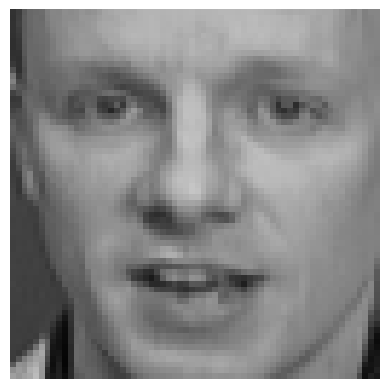

Данные: (400, 64, 64, 3) пакет: (32, 64, 64, 3)


In [2]:
faces = fetch_olivetti_faces(shuffle=True, random_state=SEED)
images = faces.images[:MAX_EXAMPLES].astype(np.float32)
subject_ids = faces.target[:MAX_EXAMPLES]  # Не входит в Dataset.
x_real = np.repeat(images[..., np.newaxis], CHANNELS, axis=-1) * 2.0 - 1.0
dataset = (tf.data.Dataset.from_tensor_slices(x_real)
           .shuffle(len(x_real), seed=SEED, reshuffle_each_iteration=True)
           .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
first_batch = next(iter(dataset))
assert x_real.shape == (MAX_EXAMPLES, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
assert first_batch.shape == (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
assert np.isfinite(x_real).all() and -1 <= x_real.min() <= x_real.max() <= 1
assert np.allclose(x_real[..., 0], x_real[..., 1]) and np.allclose(x_real[..., 1], x_real[..., 2])
plt.imshow((x_real[0] + 1) / 2, vmin=0, vmax=1); plt.axis('off'); plt.show()
print('Данные:', x_real.shape, 'пакет:', first_batch.shape)

## Этап 3. Свёрточный генератор

**Требуется:** реализовать генератор, который преобразует
$(B,100)$ в $(B,64,64,3)$: `Dense(4·4·512)`, reshape и четыре
`Conv2DTranspose` с промежуточными BatchNormalization и ReLU. На
последнем слое используйте `tanh`.

**Контрольная точка:** диагностический проход выдаёт конечные значения
в диапазоне $[-1,1]$, а не плоский вектор пикселей.

Генератор сначала получает одну карточку из 100 чисел на лицо. Он
делает маленькую внутреннюю картинку, а затем несколько раз увеличивает
её. Транспонированная свёртка — не волшебное увеличение готовой
фотографии: она применяет обучаемые правила и создаёт новые пиксели.
`BatchNormalization` помогает числам внутри сети оставаться удобного
масштаба, а `tanh` ограничивает финальные RGB-значения.

In [3]:
def make_generator():
    init = tf.keras.initializers.RandomNormal(stddev=0.02)
    model = tf.keras.Sequential(name='olivetti_generator')
    model.add(tf.keras.Input(shape=(NOISE_DIM,)))
    model.add(tf.keras.layers.Dense(4 * 4 * 512, use_bias=False, kernel_initializer=init))
    model.add(tf.keras.layers.Reshape((4, 4, 512)))
    model.add(tf.keras.layers.BatchNormalization())
    model.add(tf.keras.layers.ReLU())
    for channels in (256, 128, 64):
        model.add(tf.keras.layers.Conv2DTranspose(channels, 4, strides=2, padding='same',
                                                  use_bias=False, kernel_initializer=init))
        model.add(tf.keras.layers.BatchNormalization())
        model.add(tf.keras.layers.ReLU())
    model.add(tf.keras.layers.Conv2DTranspose(CHANNELS, 4, strides=2, padding='same',
                                              activation='tanh', kernel_initializer=init))
    return model

generator = make_generator()
z_check = tf.random.normal((BATCH_SIZE, NOISE_DIM))
fake_check = generator(z_check, training=False)
assert fake_check.shape == (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
assert bool(tf.reduce_all(tf.math.is_finite(fake_check)))
assert bool(tf.reduce_all(tf.abs(fake_check) <= 1))
print('G:', z_check.shape, '→', fake_check.shape)

G: (32, 100) → (32, 64, 64, 3)


## Этап 4. Свёрточный дискриминатор и логиты

**Требуется:** собрать дискриминатор из свёрток со stride 2,
LeakyReLU, Dropout и завершающего `Dense(1)` **без sigmoid**. Его
выход — логит формы $(B,1)$. Поэтому в BCE надо указать
`from_logits=True`.

**Контрольная точка:** не проверяйте логиты на принадлежность
интервалу $(0,1)$: это свойство вероятности после sigmoid, но не
самого логита.

Логит — просто оценка до перевода в вероятность. Большой положительный
логит говорит «скорее настоящее», большой отрицательный — «скорее
синтетическое». `BinaryCrossentropy(from_logits=True)` сама выполняет
нужный перевод надёжнее, чем отдельный sigmoid. D не определяет, кто
изображён на лице: он отвечает только на вопрос об источнике картинки.

In [4]:
def make_discriminator():
    init = tf.keras.initializers.RandomNormal(stddev=0.02)
    model = tf.keras.Sequential(name='olivetti_discriminator')
    model.add(tf.keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS)))
    for channels in (64, 128, 256, 512):
        model.add(tf.keras.layers.Conv2D(channels, 4, strides=2, padding='same',
                                         kernel_initializer=init))
        model.add(tf.keras.layers.LeakyReLU(negative_slope=0.2))
        model.add(tf.keras.layers.Dropout(0.3))
    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense(1))  # Логит без sigmoid.
    return model

discriminator = make_discriminator()
logits = discriminator(first_batch, training=False)
assert logits.shape == (BATCH_SIZE, 1)
assert bool(tf.reduce_all(tf.math.is_finite(logits)))
bce = tf.keras.losses.BinaryCrossentropy(from_logits=True)
generator_optimizer = tf.keras.optimizers.Adam(LEARNING_RATE, beta_1=BETA_1)
discriminator_optimizer = tf.keras.optimizers.Adam(LEARNING_RATE, beta_1=BETA_1)
print('D:', logits.shape, 'логиты; BCE from_logits=True')

D: (32, 1) логиты; BCE from_logits=True


## Этап 5. Раздельные шаги оптимизации

**Требуется:** реализовать два `GradientTape`. В шаге дискриминатора
используйте `stop_gradient(G(z))`, реальные цели 0.9 и синтетические
0. В шаге генератора используйте новую выборку шума и целевое значение
1; градиент должен пройти через дискриминатор к изображению, но
оптимизатор меняет только переменные генератора.

**Проверка:** обе потери — конечные скаляры; после каждого подшага
изменяется только соответствующий набор параметров.

**Сначала учится D.** Настоящие лица имеют цель 0.9, рисунки — 0.
`stop_gradient` превращает рисунок в «готовую картинку» именно для
этой фазы: обратная стрелка к G выключена. **Затем учится G.** Новый
шум создаёт новый рисунок, а его цель равна 1. D остаётся полезным
проверяющим, который сообщает направление улучшения, но второй
оптимизатор получает только веса G.

`training=False` у D означает «не включать его Dropout», а не «не
передавать замечание художнику». Стрелка градиента к G сохраняется;
она исчезла бы только при `stop_gradient` в этой второй фазе.

Здесь D возвращает логит $\ell$, то есть свободную оценку до
вероятности. Мысленно вероятность равна
$p=\sigma(\ell)=1/(1+e^{-\ell})$, а ошибка одной картинки и цели $y$
записывается так:

$$
\operatorname{BCE}(y,p)=-y\log p-(1-y)\log(1-p).
$$

`BinaryCrossentropy(from_logits=True)` получает логит и объединяет
sigmoid с этой формулой устойчиво; отдельный sigmoid перед loss был бы
неверным дублированием.

### Математический и API-контракт

**Сначала прочитайте маршрут одного пакета, а уже потом заполняйте
`TODO(student)`.**

![Два независимых обновления GAN: обучение дискриминатора, затем обучение генератора](assets/diagrams/gan_two_phase_training.svg)

На рисунке синие блоки — данные, зелёные — сети с параметрами, красные
— потери-скаляры. Ваш код будет создавать временные синие тензоры,
получать два красных числа и передавать Adam только пары градиентов с
зелёными параметрами. Ни шум, ни изображения, ни классовые метки лиц
не являются объектами оптимизации.

Пусть $\theta_G$ — все веса генератора, а $\theta_D$ — все веса
дискриминатора. Потеря — одно итоговое число. Её производная по весу
отвечает, в какую сторону слегка изменить этот вес; общий шаг имеет вид

$$
\theta\leftarrow\theta-\eta\nabla_\theta\mathcal L.
$$

В первой фазе составьте $\mathcal L_D$ из BCE настоящих лиц с целью
0.9 и синтетических с целью 0, после чего берите градиент только по
$\theta_D$. Во второй составьте
$\mathcal L_G=\operatorname{BCE}(1,D(G(\mathbf z_G)))$ и берите
градиент только по $\theta_G$. Шум $\mathbf z_G$ — новый вход, а не
параметр, который оптимизатор должен сохранять.

### Как `GradientTape` помогает выполнить математическое правило

![Жизненный цикл GradientTape от прямого прохода до обновления Adam](assets/diagrams/tensorflow_gradient_tape.svg)

`GradientTape` записывает прямой путь до одной потери. Пока активен
блок `with`, TensorFlow строит временный граф дифференцируемых операций
и автоматически наблюдает задействованные обучаемые `tf.Variable`.
Вызов `tape.gradient(loss, variables)` идёт по этому графу назад и
возвращает одну производную на каждый указанный вес; её форма совпадает
с формой этого веса. Наконец, `zip` формирует пары «производная, вес»,
а `apply_gradients` передаёт их Adam. Поэтому именно список переменных
в этом вызове определяет, что обновляется.

У обычного непостоянного tape есть один обратный проход: после
`gradient(...)` его запись освобождается. Не нужно вручную строить
якобианы всех RGB-пикселей и весов; TensorFlow эффективно передаёт их
действие на градиент скалярной потери.

В фазе G путь остаётся математически равным

$$
\frac{\partial\mathcal L_G}{\partial\theta_G}
=\frac{\partial\mathcal L_G}{\partial D}
\frac{\partial D}{\partial G}
\frac{\partial G}{\partial\theta_G}.
$$

Это **цепное правило**: изменение веса G меняет картинку, картинка
меняет ответ D, а ответ D меняет итоговую потерю. D участвует в этой
цепочке как измерительный прибор, но его веса не стоят в списке
`variables`, поэтому их поправка не применяется.

### Один мини-пакет: спецификация будущего TensorFlow-кода

В самостоятельной реализации используйте следующие математические
роли и имена. Ничего из этой таблицы не надо оптимизировать, кроме
параметров $\theta_G$ и $\theta_D$.

| Объект | Имя, которое следует завести | Форма | Что проверять |
| --- | --- | --- | --- |
| Настоящие лица $\mathbf x_{\rm real}$ | `real_images` | `(B,64,64,3)` | Значения `[-1,1]`, цель D — 0.9. |
| Шум D $\mathbf z_D$ | `discriminator_noise` | `(B,100)` | Это временный вход генератора. |
| Подделка для D | `fake_images` | `(B,64,64,3)` | После `stop_gradient`; цель D — 0. |
| Логиты D | `real_logits`, `fake_logits` | `(B,1)` | Могут быть любыми вещественными числами. |
| Потеря D | `d_loss` | скаляр | Градиент берётся по `discriminator.trainable_variables`. |
| Шум G $\mathbf z_G$ | `generator_noise` | `(B,100)` | Это новая независимая выборка. |
| Изображение G | `generated_images` | `(B,64,64,3)` | Не отсоединяется от графа. |
| Потеря G | `g_loss` | скаляр | Градиент берётся по `generator.trainable_variables`. |

**Контроль перед переходом к следующей ячейке.** Разделите в уме
объекты таблицы на данные, параметры и скаляры. `fake_images` после
`stop_gradient` всё ещё имеет форму `(B,64,64,3)` и те же пиксели, но
перестаёт быть путём к $\theta_G$ только в фазе D. Во второй фазе
`generated_images` нельзя отсоединять: иначе `g_loss` не сможет дать
генератору никакого замечания.

**Порядок, который надо увидеть в своём коде.** Сначала первый tape
должен закончиться `d_loss`; следующий вызов `gradient` получает только
список весов D. Потом создаётся второй tape и новый шум; он заканчивается
`g_loss`, а `gradient` получает только список весов G. `zip` не меняет
данные — он лишь соединяет производную правильной формы с её весом.
Только `apply_gradients` делает шаг Adam и действительно изменяет сеть.

Для проверки обратного пути используйте запись

$$
\nabla_{\theta_G}\mathcal L_G=
J_{G,\theta_G}^{\mathsf T}J_{D,\mathbf x}^{\mathsf T}
\nabla_{\ell}\mathcal L_G.
$$

Якобиан — таблица локальных влияний. TensorFlow не материализует
огромные якобианы для RGB-изображений, а вычисляет их нужное действие
на градиент ошибки автоматически во время `tape.gradient`.

In [5]:
@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    z_d = tf.random.normal((batch_size, NOISE_DIM))
    with tf.GradientTape() as tape_d:
        fake = tf.stop_gradient(generator(z_d, training=False))
        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(fake, training=True)
        loss_d = 0.5 * (bce(tf.ones_like(real_logits) * REAL_LABEL, real_logits)
                        + bce(tf.zeros_like(fake_logits), fake_logits))
    grads_d = tape_d.gradient(loss_d, discriminator.trainable_variables)
    discriminator_optimizer.apply_gradients(zip(grads_d, discriminator.trainable_variables))

    z_g = tf.random.normal((batch_size, NOISE_DIM))
    with tf.GradientTape() as tape_g:
        generated = generator(z_g, training=True)
        logits_g = discriminator(generated, training=False)
        loss_g = bce(tf.ones_like(logits_g), logits_g)
    grads_g = tape_g.gradient(loss_g, generator.trainable_variables)
    generator_optimizer.apply_gradients(zip(grads_g, generator.trainable_variables))
    return loss_d, loss_g

assert set(map(id, generator.trainable_variables)).isdisjoint(map(id, discriminator.trainable_variables))
print('Две независимые группы параметров и два оптимизатора.')

Две независимые группы параметров и два оптимизатора.


## Этап 6. Наблюдение генераций и выводы

**Требуется:** обучить DCGAN, сохранять сетку фиксированных шумовых
векторов через равные интервалы, построить обе истории потерь и
объяснить разнообразие либо коллапс мод. Не считайте идентификаторы
людей показателем качества GAN.

**Итоговая самопроверка:** шум `(B,100)`, изображения `(B,64,64,3)`,
логиты `(B,1)`, значения потерь конечны, метки субъектов не участвовали
в обучении.

Используйте один `fixed_noise` для всех сеток. Это одинаковые задания
для художника в начале и конце опыта; тогда видна работа обучения, а
не смена карточки. Для вывода на экран верните `[-1,1]` к `[0,1]`.
Линии потерь — полезный дневник, но не оценка красоты: смотрите на них
вместе с разнообразием лиц и отсутствием чёрных/одинаковых кадров.

In [6]:
import csv

tf.keras.utils.set_random_seed(SEED + 1)
fixed_noise = tf.random.normal((64, NOISE_DIM))
history = []

def save_grid(epoch):
    generated = np.clip((generator(fixed_noise, training=False).numpy() + 1) / 2, 0, 1)
    fig, axes = plt.subplots(8, 8, figsize=(10, 10))
    for ax, image in zip(axes.flat, generated):
        ax.imshow(image, vmin=0, vmax=1)
        ax.axis('off')
    fig.subplots_adjust(wspace=0.02, hspace=0.02)
    fig.savefig(ARTIFACT_DIR / f'generated_epoch_{epoch:03d}.png', dpi=120, bbox_inches='tight')
    plt.close(fig)

for epoch in range(1, EPOCHS + 1):
    losses = [tuple(float(x.numpy()) for x in train_step(batch)) for batch in dataset]
    mean_d, mean_g = np.mean(losses, axis=0)
    assert np.isfinite((mean_d, mean_g)).all()
    history.append((epoch, mean_d, mean_g))
    if epoch == 1 or epoch % 20 == 0 or epoch == EPOCHS:
        save_grid(epoch)
        print(f'Эпоха {epoch:3d}: D={mean_d:.4f}, G={mean_g:.4f}')

with (ARTIFACT_DIR / 'losses.csv').open('w', newline='') as f:
    writer = csv.writer(f)
    writer.writerow(('epoch', 'discriminator_loss', 'generator_loss'))
    writer.writerows(history)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot([r[0] for r in history], [r[1] for r in history], label='D')
ax.plot([r[0] for r in history], [r[2] for r in history], label='G')
ax.set(xlabel='Эпоха', ylabel='BCE', title='Olivetti Faces DCGAN')
ax.legend(); ax.grid(alpha=0.3)
fig.savefig(ARTIFACT_DIR / 'losses.png', dpi=160, bbox_inches='tight')
plt.close(fig)
print('Последняя эпоха:', history[-1])

Эпоха   1: D=0.5502, G=0.2651


Эпоха  20: D=0.1667, G=0.0144


Эпоха  40: D=0.4909, G=0.5824


Эпоха  60: D=0.6263, G=0.8032


Эпоха  80: D=0.4516, G=0.6565


Эпоха 100: D=0.4997, G=0.9843


Эпоха 120: D=0.3428, G=0.6162
Последняя эпоха: (120, np.float64(0.3427823277620169), np.float64(0.6162240436443915))


## Итог выполненного запуска

DCGAN обучен 120 эпох на 400 изображениях Olivetti Faces, устройство CPU. Финальные потери D/G: 0,343/0,616. Синтетические лица стали узнаваемыми, но многие похожи между собой: есть признаки ограниченного разнообразия (коллапса мод). Повторение серого канала три раза не добавляет цветовой информации.

- [Сетка лиц после 120 эпох](artifacts/olivetti_face_gan_tensorflow/generated_epoch_120.png)
- [График двух потерь](artifacts/olivetti_face_gan_tensorflow/losses.png)
- Полная история: `artifacts/olivetti_face_gan_tensorflow/losses.csv`